In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import sys

print(sys.executable)

c:\Users\abuya\Desktop\FUTURE_DS_01\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

print("Python environment:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Setup completed successfully!")

Python environment: c:\Users\abuya\Desktop\FUTURE_DS_01\.venv\Scripts\python.exe
Pandas version: 3.0.6
NumPy version: 2.5.4
Setup completed successfully!


In [4]:
from pathlib import Path

dataset_folder = Path("dataset")

print("Files inside dataset folder:")
print(list(dataset_folder.iterdir()))

Files inside dataset folder:
[WindowsPath('dataset/Sample - Superstore.csv.xlsx')]


In [5]:
import pandas as pd
from pathlib import Path

data_file = Path("dataset") / "Sample - Superstore.csv.xlsx"

df = pd.read_excel(data_file)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           

In [7]:
print("Missing values in each column:")
display(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

Missing values in each column:


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


Total missing values: 0

Exact duplicate rows: 0


In [8]:

# Understand the numerical columns
print("Statistical summary of numerical columns:")
display(df[["Sales", "Quantity", "Discount", "Profit"]].describe())

Statistical summary of numerical columns:


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [9]:

# Calculate key business performance indicators

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("BUSINESS PERFORMANCE SUMMARY")
print("-" * 35)
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Unique Orders: {total_orders:,}")
print(f"Total Unique Customers: {total_customers:,}")

BUSINESS PERFORMANCE SUMMARY
-----------------------------------
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Quantity Sold: 37,873
Total Unique Orders: 5,009
Total Unique Customers: 793


In [10]:

print("First order date:", df["Order Date"].min())
print("Last order date:", df["Order Date"].max())

print("\nSales by region:")
display(
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

First order date: 2014-01-03 00:00:00
Last order date: 2017-12-30 00:00:00

Sales by region:


Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

In [11]:

# Check for invalid or unusual business data

print("Negative sales:", (df["Sales"] < 0).sum())
print("Zero sales:", (df["Sales"] == 0).sum())
print("Negative quantity:", (df["Quantity"] < 0).sum())
print("Negative discounts:", (df["Discount"] < 0).sum())
print("Discounts above 100%:", (df["Discount"] > 1).sum())
print("Orders shipped before order date:",
      (df["Ship Date"] < df["Order Date"]).sum())

print("\nUnique regions:", df["Region"].unique())
print("Unique categories:", df["Category"].unique())

Negative sales: 0
Zero sales: 0
Negative quantity: 0
Negative discounts: 0
Discounts above 100%: 0
Orders shipped before order date: 0

Unique regions: <StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
Unique categories: <StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


In [12]:

# Sales and profit by product category

category_performance = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_performance.round(2))

,Total_Sales,Total_Profit,Quantity_Sold
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906


In [13]:

# Regional business performance

region_performance = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

region_performance["Profit_Margin_%"] = (
    region_performance["Total_Profit"]
    / region_performance["Total_Sales"]
    * 100
)

display(region_performance.round(2))

,Total_Sales,Total_Profit,Quantity_Sold,Profit_Margin_%
Region,,,,
West,725457.82,108418.45,12266,14.94
East,678781.24,91522.78,10618,13.48
Central,501239.89,39706.36,8780,7.92
South,391721.90,46749.43,6209,11.93


In [14]:

# Top 10 products by sales

top_products = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

display(top_products.round(2))

,Total_Sales,Total_Profit,Quantity_Sold
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00,39
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98,48
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27


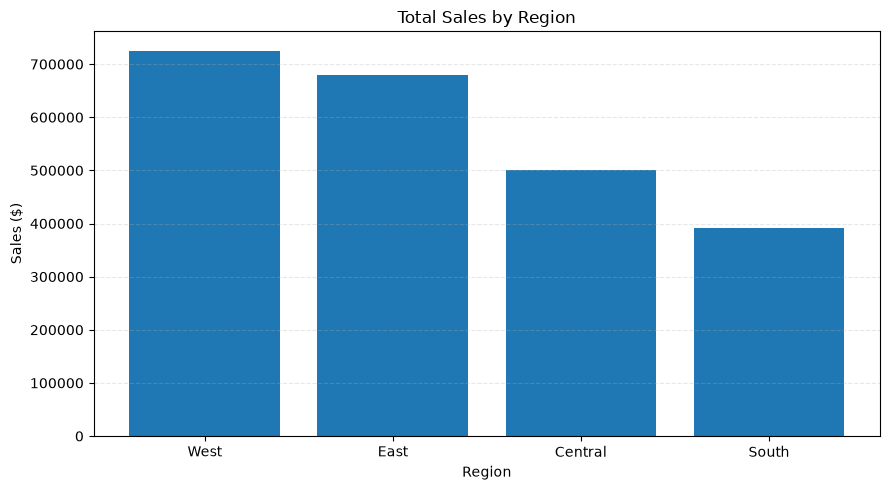

In [15]:

import matplotlib.pyplot as plt

# Prepare regional sales data
regional_sales = region_performance.sort_values(
    "Total_Sales", ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    regional_sales.index,
    regional_sales["Total_Sales"]
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("output/sales_by_region.png", dpi=300)
plt.show()

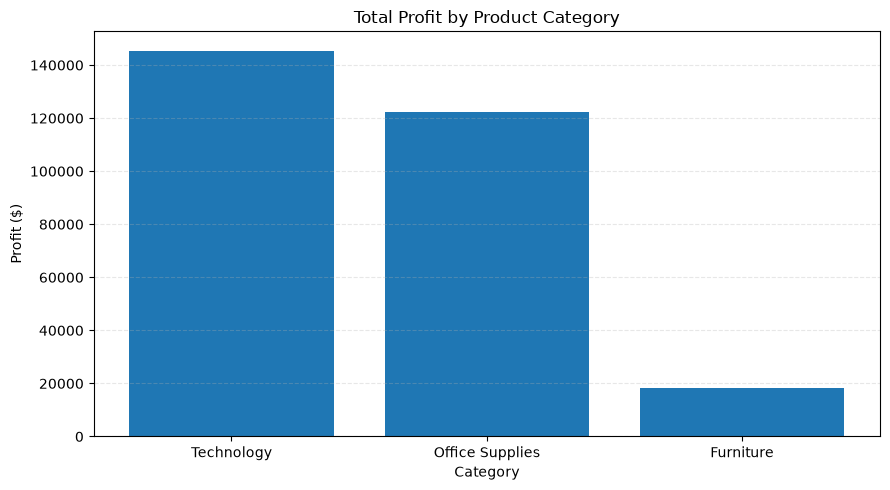

In [16]:

# Compare total profit by category

category_profit = category_performance.sort_values(
    "Total_Profit", ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    category_profit.index,
    category_profit["Total_Profit"]
)

plt.title("Total Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit ($)")
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("output/profit_by_category.png", dpi=300)
plt.show()

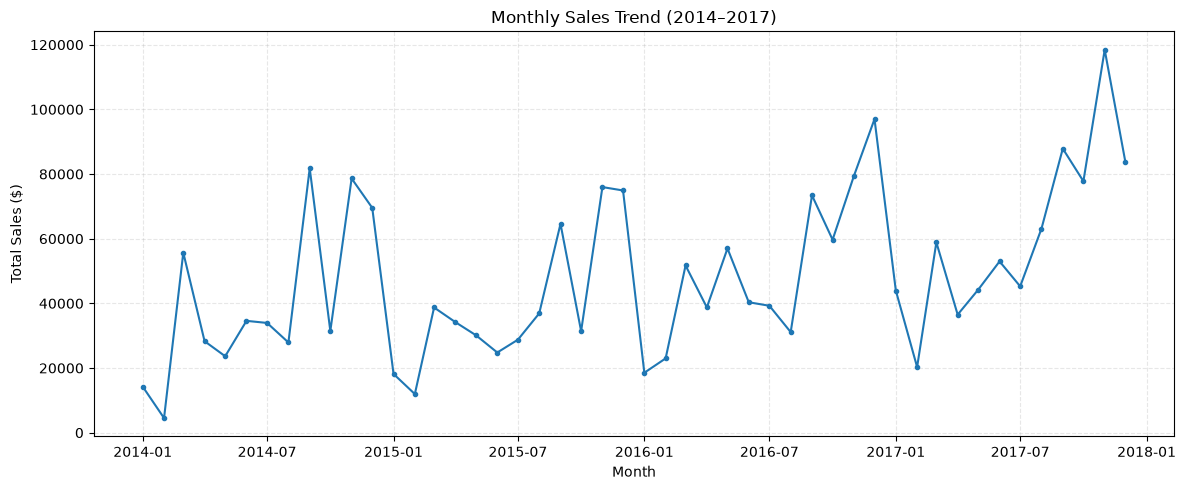

In [17]:

# Monthly sales trend

df["Order Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Order Month")["Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    markersize=3
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("output/monthly_sales_trend.png", dpi=300)
plt.show()

In [18]:

# Identify products with the lowest total profit

product_profit = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Profit", ascending=True)
)

loss_making_products = product_profit.head(10)

display(loss_making_products.round(2))

,Total_Sales,Total_Profit,Quantity_Sold
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,9
Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,18
Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.64,-2876.12,27
Bush Advantage Collection Racetrack Conference Table,9544.72,-1934.40,33
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
Martin Yale Chadless Opener Electric Letter Opener,16656.20,-1299.18,22
Balt Solid Wood Round Tables,6518.75,-1201.06,19


In [19]:

# Export analysis results to CSV files

category_performance.to_csv("output/category_performance.csv")
region_performance.to_csv("output/region_performance.csv")
top_products.to_csv("output/top_10_products.csv")
loss_making_products.to_csv("output/loss_making_products.csv")

monthly_sales.to_csv("output/monthly_sales.csv", header=["Total_Sales"])

print("Analysis tables saved successfully in the output folder.")

Analysis tables saved successfully in the output folder.


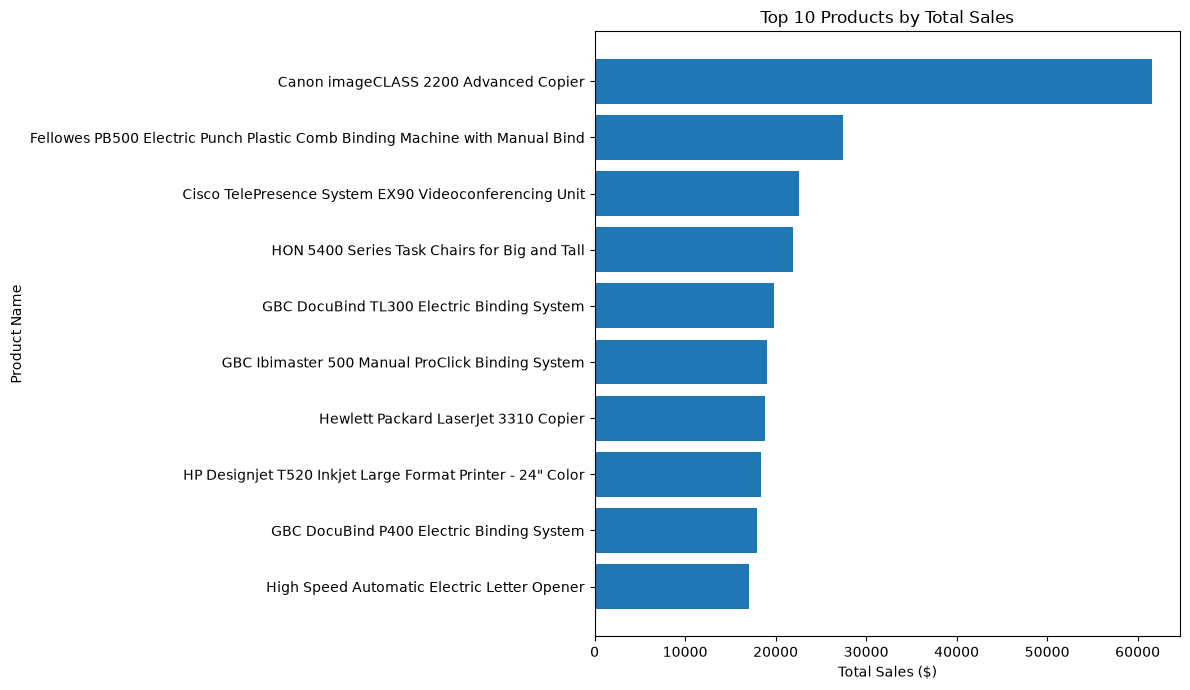

In [20]:

# Visualize the top 10 products by sales

top_products_chart = top_products.sort_values(
    "Total_Sales", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_products_chart.index,
    top_products_chart["Total_Sales"]
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Name")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()

plt.savefig("output/top_10_products_chart.png", dpi=300)
plt.show()

In [21]:

# Overall business performance metrics

overall_profit_margin = total_profit / total_sales * 100
average_order_value = total_sales / total_orders
average_profit_per_order = total_profit / total_orders

print("OVERALL BUSINESS PERFORMANCE")
print("-" * 40)
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Average Profit per Order: ${average_profit_per_order:,.2f}")

OVERALL BUSINESS PERFORMANCE
----------------------------------------
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Overall Profit Margin: 12.47%
Average Order Value: $458.61
Average Profit per Order: $57.18


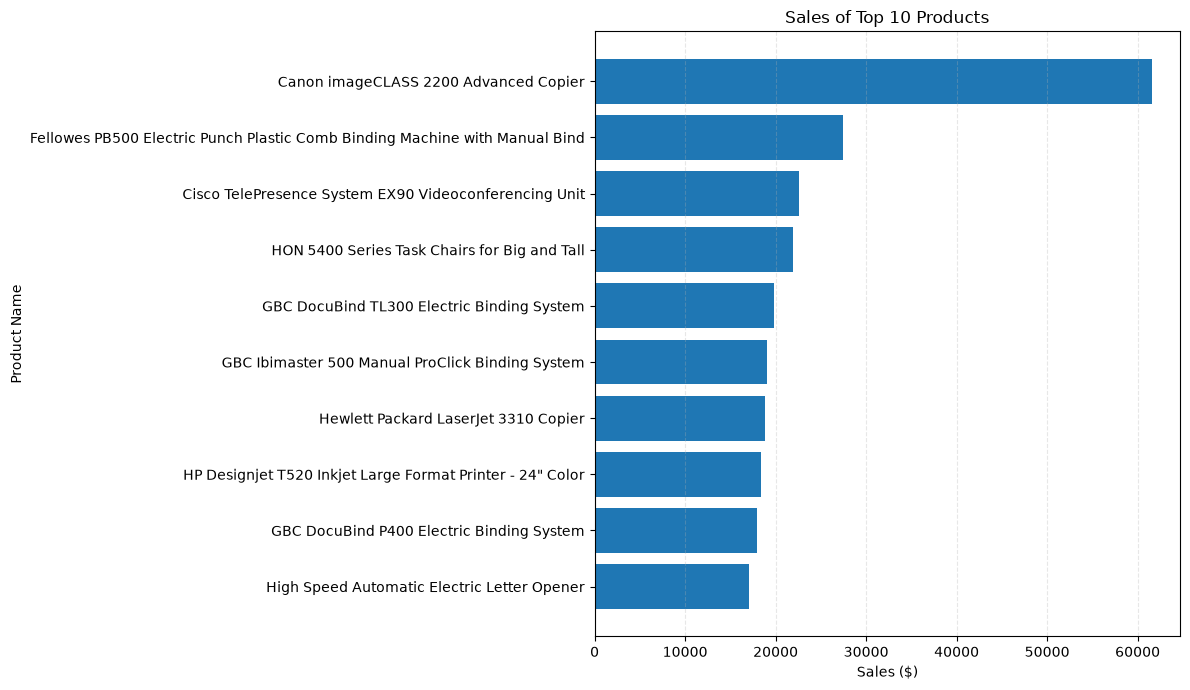

In [22]:

# Compare sales and profit for the top 10 products

top_products_comparison = top_products.sort_values(
    "Total_Sales", ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_products_comparison.index,
    top_products_comparison["Total_Sales"],
    label="Sales"
)

ax.set_title("Sales of Top 10 Products")
ax.set_xlabel("Sales ($)")
ax.set_ylabel("Product Name")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("output/top_products_sales_comparison.png", dpi=300)
plt.show()

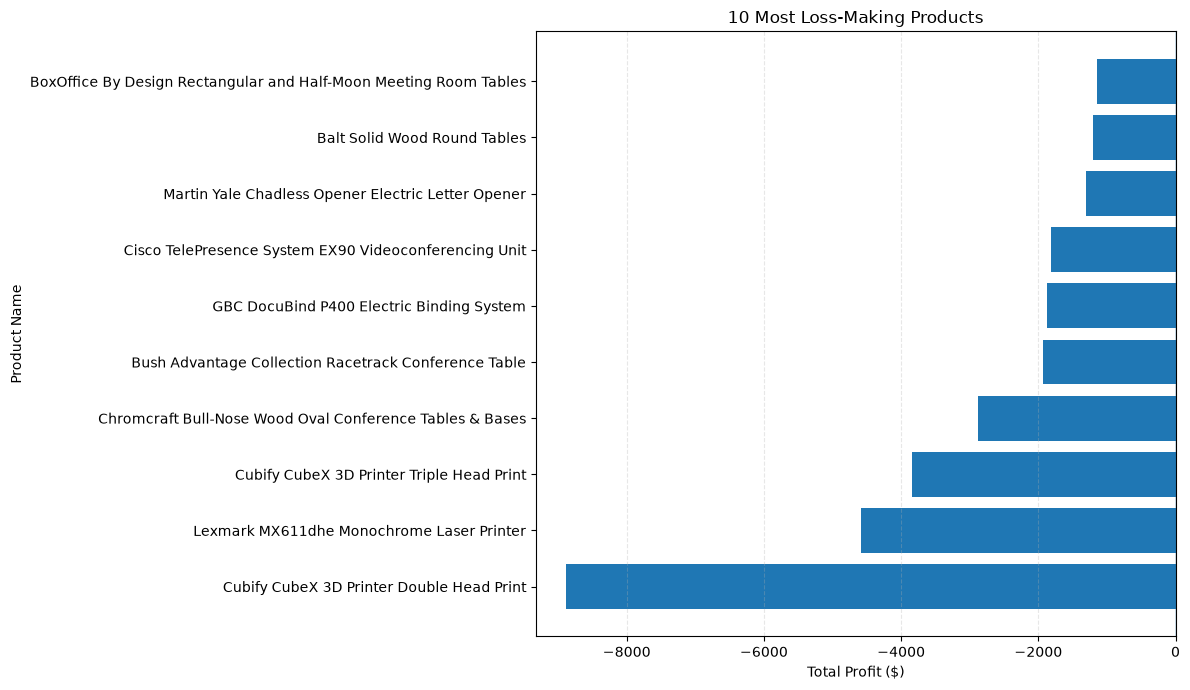

In [23]:

# Visualize the 10 products with the lowest profit

loss_chart = loss_making_products.sort_values(
    "Total_Profit", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    loss_chart.index,
    loss_chart["Total_Profit"]
)

plt.axvline(0, linewidth=1)
plt.title("10 Most Loss-Making Products")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Name")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("output/loss_making_products_chart.png", dpi=300)
plt.show()